In [128]:
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

In [130]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("../data")      # raw and clean CSV files go here
FIG_DIR = Path("../figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 33


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [131]:
# Download (or reuse from the cache) the CSV file
csv_path = kh.dataset_download(
    "harlfoxem/housesalesprediction",
    path="kc_house_data.csv",
)

# Check if the file is zipped
is_zip = zipfile.is_zipfile(csv_path)

# Read CSV
df = pd.read_csv(
    csv_path,
    compression="zip" if is_zip else None
)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")


Loaded 21,613 rows and 21 columns


In [132]:
raw_path = DATA_DIR / "kc_house_data_raw.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data already saved in ../data/kc_house_data_raw.csv


In [133]:
df.shape

(21613, 21)

In [134]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [156]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [137]:
df.describe(include="all")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,"21,613.00",21613,"21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00"
unique,NaN,372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,20140623T000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,"4,580,301,520.86",NaN,"540,088.14",3.37,2.11,"2,079.90","15,106.97",1.49,0.01,0.23,3.41,7.66,"1,788.39",291.51,"1,971.01",84.40,"98,077.94",47.56,-122.21,"1,986.55","12,768.46"
std,"2,876,565,571.31",NaN,"367,127.20",0.93,0.77,918.44,"41,420.51",0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,53.51,0.14,0.14,685.39,"27,304.18"
min,"1,000,102.00",NaN,"75,000.00",0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,"1,900.00",0.00,"98,001.00",47.16,-122.52,399.00,651.00
25%,"2,123,049,194.00",NaN,"321,950.00",3.00,1.75,"1,427.00","5,040.00",1.00,0.00,0.00,3.00,7.00,"1,190.00",0.00,"1,951.00",0.00,"98,033.00",47.47,-122.33,"1,490.00","5,100.00"
50%,"3,904,930,410.00",NaN,"450,000.00",3.00,2.25,"1,910.00","7,618.00",1.50,0.00,0.00,3.00,7.00,"1,560.00",0.00,"1,975.00",0.00,"98,065.00",47.57,-122.23,"1,840.00","7,620.00"
75%,"7,308,900,445.00",NaN,"645,000.00",4.00,2.50,"2,550.00","10,688.00",2.00,0.00,0.00,4.00,8.00,"2,210.00",560.00,"1,997.00",0.00,"98,118.00",47.68,-122.12,"2,360.00","10,083.00"


In [138]:
df_clean = df.copy()

In [139]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 0


In [140]:
# Is the index column unique? (every value different)
print(f"Is 'id' unique? {df_clean['id'].is_unique}")

# Look for duplicates in all the other columns
n_duplicates = df_clean.drop(columns="id").duplicated().sum()
share = n_duplicates / len(df_clean)
print(f"Duplicated rows when ignoring 'id': {n_duplicates:,} ({share:.0%} of the dataset!)")

Is 'id' unique? False
Duplicated rows when ignoring 'id': 0 (0% of the dataset!)


In [141]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
id,0,0.00
grade,0,0.00
sqft_living15,0,0.00
long,0,0.00
lat,0,0.00
zipcode,0,0.00
yr_renovated,0,0.00
yr_built,0,0.00
sqft_basement,0,0.00
sqft_above,0,0.00


Figure saved to ../figures/01_missing_values.png


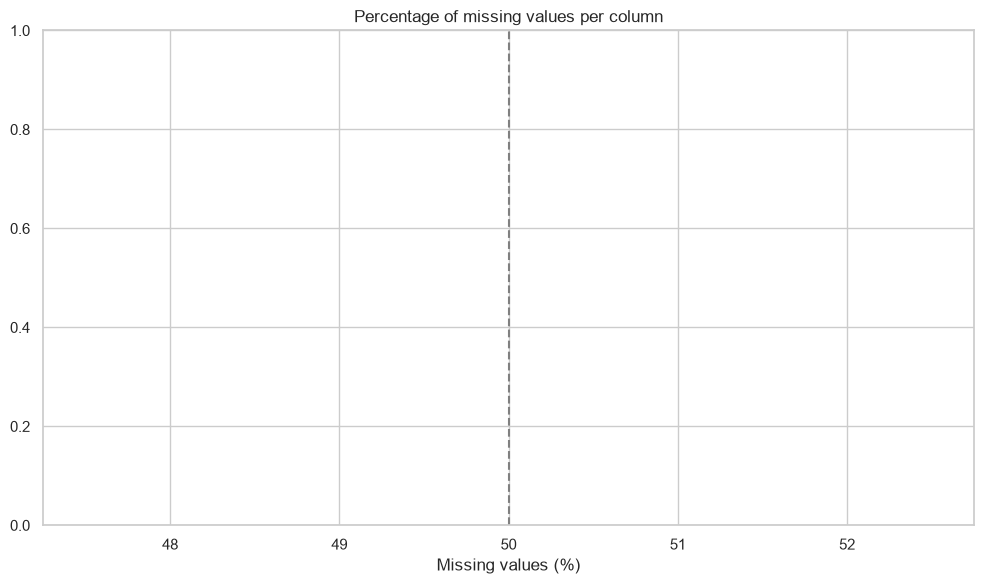

In [142]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

In [143]:
columns_to_drop = ["waterfront", "view"]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (19): ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [144]:
df_clean["date"] = pd.to_datetime(df_clean['date'], format='%Y%m%dT%H%M%S')


In [145]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[us]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   condition      21613 non-null  int64         
 9   grade          21613 non-null  int64         
 10  sqft_above     21613 non-null  int64         
 11  sqft_basement  21613 non-null  int64         
 12  yr_built       21613 non-null  int64         
 13  yr_renovated   21613 non-null  int64         
 14  zipcode        21613 non-null  int64         
 15  lat            21613 non-null 

Figure saved to ../figures/02_b4Percentile_values.png


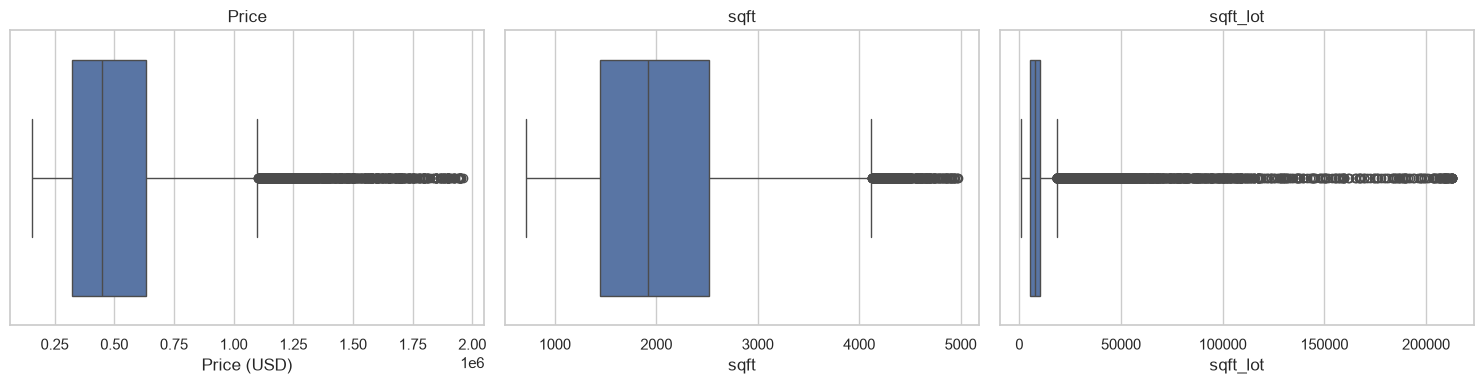

In [160]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["sqft_lot"], ax=axes[2])
axes[2].set_title("sqft_lot")
axes[2].set_xlabel("sqft_lot")

plt.tight_layout()
save_fig("02_b4Percentile_values")
plt.show()

In [147]:
price = df_clean["price"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)

# Percentile rule
p01, p99 = price.quantile([0.01, 0.99])
pct_outliers = (price < p01) | (price > p99)

print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} USD -> removes {iqr_outliers.sum():,} listings")
print(f"Percentile rule: keep {p01:,.1f} to {p99:,.1f} USD -> removes {pct_outliers.sum():,} listings")

IQR rule:        keep -162,625.0 to 1,129,575.0 USD -> removes 1,146 listings
Percentile rule: keep 153,500.4 to 1,964,400.0 USD -> removes 434 listings


In [149]:
rows_before = len(df_clean)

# 1) Remove listings without a price (our target variable)
df_clean = df_clean.dropna(subset=["price"])
print(f"Removed {rows_before - len(df_clean):,} listings without a price")


def within_percentiles(series, low=0.01, high=0.99):
    # True for values between the low and high percentiles. Missing values are kept (True):
    # we do not want to delete a row just because one of the columns is unknown.
    lower, upper = series.quantile([low, high])
    return series.isna() | series.between(lower, upper)


# 2) Percentile rule on the three main numeric columns. & means "AND": all three must be OK
keep = (
    within_percentiles(df_clean["price"])
    & within_percentiles(df_clean["sqft_living"])
    & within_percentiles(df_clean["sqft_lot"])
)
rows_before_outliers = len(df_clean)
df_clean = df_clean[keep].reset_index(drop=True)
print(f"Removed {rows_before_outliers - len(df_clean):,} outlier listings")
print(f"Rows left: {len(df_clean):,}")

Removed 0 listings without a price
Removed 1,140 outlier listings
Rows left: 20,473


Figure saved to ../figures/03_new_values.png


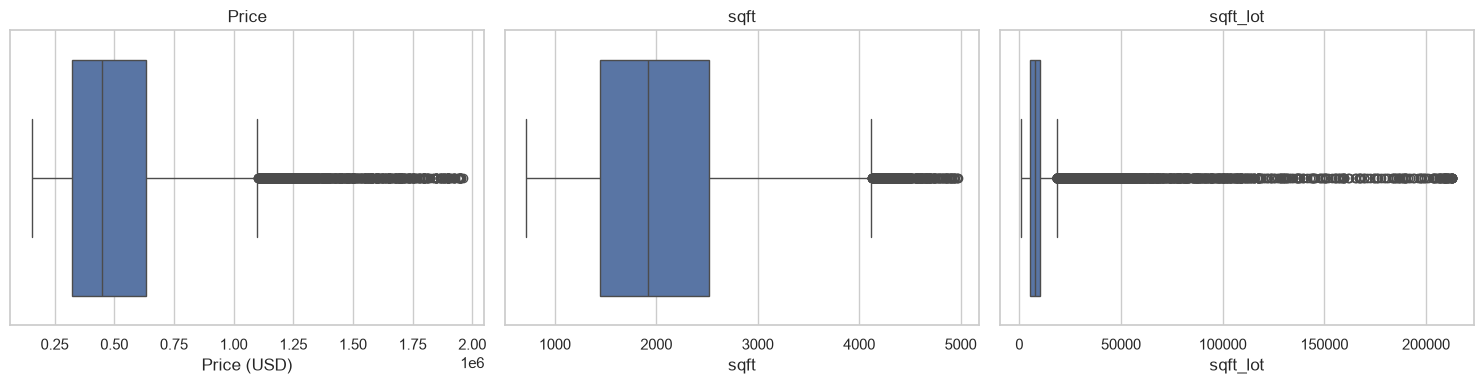

In [159]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["sqft_lot"], ax=axes[2])
axes[2].set_title("sqft_lot")
axes[2].set_xlabel("sqft_lot")

plt.tight_layout()
save_fig("03_new_values")
plt.show()

In [153]:
missing_report(df_clean).head(12)

,n_missing,pct_missing
id,0,0.00
sqft_above,0,0.00
sqft_living15,0,0.00
long,0,0.00
lat,0,0.00
zipcode,0,0.00
yr_renovated,0,0.00
yr_built,0,0.00
sqft_basement,0,0.00
grade,0,0.00


In [157]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"21,613.00","20,473.00"
columns,21.00,19.00
numeric columns,20.00,18.00
average % missing,0.00,0.00
memory (MB),4.84,3.11


In [158]:
clean_path = DATA_DIR / "kc_houses_data_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Clean data saved to {clean_path} ({clean_path.stat().st_size / 1e6:.1f} MB)")

Clean data saved to ../data/kc_houses_data_clean.csv (2.1 MB)
